# Exercise 4: Tokens, Embeddings & Self-Attention

# Prerequisites
Please install Python and the required libraries for this exercise, or do it in Google Colab. Parts 1–3 only need **NumPy** (and matplotlib for one plot). The last task of Part 3 compares your implementation with [PyTorch](https://pytorch.org/get-started/locally/), as used in Exercise 3 (already installed in Colab).

The import statements of the solution we prepared are specified below, however feel free to use any other library.

This exercise follows Lecture 4: a transformer does not read text, but a matrix with one vector per token. We build this input step by step (**tokens → IDs → vectors → position**) and then compute **self-attention**, the core of the transformer.

**Total: 20 points.** Questions are part of the points, answer them in 1–3 sentences in the markdown cells.

In [1]:
# These are the libraries that we used - feel free to use others if you want
import numpy as np
import matplotlib.pyplot as plt
import torch

np.random.seed(0)

# Group 7: Shang La, Christine Engelmann, Ihsane Darssi

# 1)
Tokenization. (5 points)

Neural networks can't process text directly, they only work with numbers. Tokenization is the first step that bridges human language and machine learning (Lecture 4, Part 3): the text is split into **tokens**, and each token is replaced by an **ID** from a vocabulary.

Build a basic word-level tokenizer class that can:

- **Build a vocabulary** from a list of sentences (lowercase the text and split at spaces; each new word gets the next free ID).
- **Encode** a sentence into a list of token IDs. If `max_length` is given, pad the list with `0` up to that length, so that all encoded sentences have the same length.
- **Decode** a list of token IDs back into a sentence.

Include the special token `<UNK>` (unknown) with ID `0` for words that are not in the vocabulary.

In [100]:
class SimpleTokenizer:
    def __init__(self):
        # Your code
        self.word2id = {"<UNK>": 0}
        self.id2word = {0: "<UNK>"}
        

    def build_vocab(self, sentences):
        # Your code
        for sentence in sentences:
            for word in sentence.lower().split(" "):
                if word not in self.word2id:
                    new_id = len(self.word2id)
                    self.word2id[word] = new_id
                    self.id2word[new_id] = word
        

    def encode(self, sentence, max_length=None):
        # Your code
        ids = [self.word2id.get(w, 0) for w in sentence.lower().split(" ")]
        if max_length is not None:
            ids = ids + [0] * (max_length - len(ids))
        return ids
       

    def decode(self, token_ids):
        # Your code
        return " ".join(self.id2word[i] for i in token_ids)
        

In [101]:
training_sentences = [
    "The tumour was removed because it was malignant",
    "The surgeon removed the lesion",
    "Aspirin relieves pain",
]

tokenizer = SimpleTokenizer()
# Build vocabulary
tokenizer.build_vocab(training_sentences)
print("Vocabulary:", tokenizer.word2id)

# Encode a sentence with known words only: "The surgeon removed the tumour"
ids = tokenizer.encode("The surgeon removed the tumour")
print("Encoded:", ids)                       

# Decode back
print("Decoded:", tokenizer.decode(ids))     

# Encode a sentence with an unknown word: "The polyp was removed"
print("Unknown word:", tokenizer.encode("The polyp was removed"))   

# Encode "Aspirin relieves pain" with max_length=8           
print("Padded:", tokenizer.encode("Aspirin relieves pain", max_length = 8))



Vocabulary: {'<UNK>': 0, 'the': 1, 'tumour': 2, 'was': 3, 'removed': 4, 'because': 5, 'it': 6, 'malignant': 7, 'surgeon': 8, 'lesion': 9, 'aspirin': 10, 'relieves': 11, 'pain': 12}
Encoded: [1, 8, 4, 1, 2]
Decoded: the surgeon removed the tumour
Unknown word: [1, 0, 3, 4]
Padded: [10, 11, 12, 0, 0, 0, 0, 0]


# 2)
Embeddings and position. (6 points)

In a transformer, each token ID selects one row of a learned **embedding matrix**, a vector of numbers (Lecture 4, "the embedding layer"). After training, tokens used in similar contexts end up with similar vectors.

Below is a small **hand-made** embedding table with 6 dimensions. We constructed the numbers so that related words are close to each other, let's pretend it comes from a trained model. Real embeddings are learned, have hundreds of dimensions, and single dimensions usually have no clear meaning.

In [76]:
embeddings = {
    "the":            [0.1, 0.1, 0.1, 0.1, 0.1, 0.1],
    "aspirin":        [0.9, 0.0, 0.2, 0.0, 0.4, 0.0],
    "ibuprofen":      [0.9, 0.0, 0.5, 0.0, 0.0, 0.0],
    "metformin":      [0.9, 0.0, 0.0, 0.6, 0.0, 0.0],
    "insulin":        [0.7, 0.0, 0.0, 0.8, 0.0, 0.1],
    "tumour":         [0.0, 0.9, 0.0, 0.0, 0.0, 0.3],
    "carcinoma":      [0.0, 1.0, 0.0, 0.0, 0.0, 0.2],
    "lesion":         [0.0, 0.7, 0.1, 0.0, 0.1, 0.4],
    "malignant":      [0.0, 0.9, 0.0, 0.0, 0.0, 0.0],
    "removed":        [0.1, 0.3, 0.0, 0.0, 0.0, 0.8],
    "surgeon":        [0.0, 0.2, 0.1, 0.0, 0.0, 0.9],
    "liver":          [0.0, 0.2, 0.0, 0.3, 0.0, 0.8],
    "kidney":         [0.0, 0.1, 0.0, 0.3, 0.2, 0.8],
    "osteoarthritis": [0.0, 0.1, 1.0, 0.0, 0.0, 0.1],
    "joint":          [0.0, 0.0, 0.9, 0.0, 0.0, 0.3],
    "pain":           [0.2, 0.1, 0.7, 0.0, 0.1, 0.0],
    "stiffness":      [0.0, 0.0, 0.9, 0.0, 0.1, 0.0],
    "relief":         [0.6, 0.0, 0.5, 0.0, 0.0, 0.0],
    "diabetes":       [0.0, 0.0, 0.0, 1.0, 0.2, 0.0],
    "sugar":          [0.0, 0.0, 0.0, 0.9, 0.0, 0.0],
    "hypertension":   [0.0, 0.0, 0.0, 0.2, 1.0, 0.0],
    "blood":          [0.0, 0.0, 0.0, 0.4, 0.8, 0.1],
    "pressure":       [0.0, 0.0, 0.1, 0.0, 0.9, 0.0],
}
embeddings = {word: np.array(vec) for word, vec in embeddings.items()}
d_model = 6

## a) Cosine similarity (1 point)
Implement the cosine similarity of two vectors (Lecture 4, "What training gives the embeddings"):

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

It is 1 if both vectors point in the same direction, 0 if they are orthogonal.

In [103]:
def cosine_similarity(a, b):
     # Your code
    top = np.dot(a, b)
    bottom = np.linalg.norm(a) * np.linalg.norm(b)
    sim = top/ bottom
    return sim

print(cosine_similarity(embeddings["tumour"], embeddings["carcinoma"]))  # Related words (tumour, carcinoma) have cosine close to 1 
print(cosine_similarity(embeddings["tumour"], embeddings["sugar"]))  # unrelated words (tumour, sugar) have cosine 0

0.9922778767136676
0.0


## b) Nearest words (2 points)
Write a function that returns the `k` words of the table that are most similar to a given word (excluding the word itself), together with their cosine similarity. Print the 3 nearest words of **"aspirin"** and of **"tumour"**.

In [104]:
def nearest_words(word, k=3):
    # Your code
    score = []
    for w in embeddings:
        if w != word:
            sim = cosine_similarity(embeddings[word], embeddings[w])
            score.append((w, sim))
    sorted_score = sorted(score, key=lambda p: p[1], reverse=True) 
    return sorted_score[:k]
            

# Nearest words of "aspirin" and "tumour"
print("Aspirin:", nearest_words("aspirin", 3))
print("Tumour:", nearest_words("tumour", 3))

Aspirin: [('ibuprofen', np.float64(0.879483655387299)), ('relief', np.float64(0.8153693264107683)), ('metformin', np.float64(0.7451288882921903))]
Tumour: [('carcinoma', np.float64(0.9922778767136676)), ('lesion', np.float64(0.9658342616078198)), ('malignant', np.float64(0.9486832980505139))]


## c) Positional encoding (3 points)
The embedding of a token says **which** token it is, but not **where** it is in the sentence. Self-attention (Part 3) does not use the order of the tokens either, so these two sentences would look the same to it (Lecture 4, "A problem: no sense of word order"):

- *the surgeon removed the tumour*
- *the tumour removed the surgeon*

The transformer therefore **adds** a positional encoding $p$ to each token embedding $e$, so that the input vector is $x = e + p$.

**Idea: waves over the position.** Each dimension of $p$ is a wave over the position $pos = 0, 1, 2, \dots$ of the token in the sentence, $\sin(\omega \cdot pos)$, where $\omega$ is the frequency of the wave. Every dimension gets its own frequency: a fast wave changes a lot from one token to the next, a slow wave only over long distances. Together, the values of all dimensions form a pattern that is different for each position (like the hands of a clock: seconds, minutes, hours).

**Choosing the frequencies.** The original transformer uses $d/2$ frequencies that decrease geometrically from $1$ to almost $1/10000$:

$$\omega_k = \frac{1}{10000^{2k/d}}, \qquad k = 0, 1, \dots, \tfrac{d}{2} - 1$$

where $d$ is the embedding dimension. Each frequency is used for two neighbouring dimensions, once with a sine and once with a cosine (a cosine is just a sine shifted by a quarter period, $\cos(x) = \sin(x + \pi/2)$):

$$PE(pos, 2k) = \sin(\omega_k \cdot pos) \qquad PE(pos, 2k+1) = \cos(\omega_k \cdot pos)$$

Inserting $\omega_k$ gives $\omega_k \cdot pos = \frac{pos}{10000^{2k/d}}$, which is exactly the formula in the lecture and in the original paper:

$$PE(pos, 2k) = \sin\left(\frac{pos}{10000^{2k/d}}\right) \qquad PE(pos, 2k+1) = \cos\left(\frac{pos}{10000^{2k/d}}\right)$$

So the even dimensions $0, 2, 4, \dots$ get a sine, the odd dimensions $1, 3, 5, \dots$ a cosine, and low dimensions change quickly with the position, high dimensions slowly.

- Implement `positional_encoding(n, d)`, which returns an $n \times d$ matrix whose row $pos$ is the encoding of position $pos$.
- Run the given plotting code for $n = 40$ positions and $d = 16$ dimensions.
- **Same word, different place:** compute the input vector $x = e + p$ of "tumour" in both sentences above (position 4 in the first, position 1 in the second; use $d = 6$, as in the table). Compare the two vectors with your cosine similarity, once **without** and once **with** positional encoding.

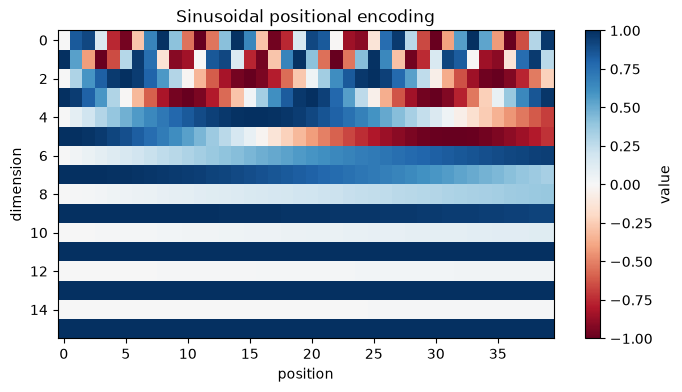

In [ ]:
def positional_encoding(n, d):
    # Your code
    pe = np.zeros((n, d))
    
    for pos in range(n):
        for k in range(d // 2):
            omega = 1 / 10000 ** (2 * k / d)
            pe[pos, 2 * k]     = np.sin(omega * pos)
            pe[pos, 2 * k + 1] = np.cos(omega * pos)
            
    return pe

pe = positional_encoding(40, 16)
plt.figure(figsize=(8, 4))
plt.imshow(pe.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("position")
plt.ylabel("dimension")
plt.colorbar(label="value")
plt.title("Sinusoidal positional encoding")
plt.show()

In [84]:
sentence_1 = "the surgeon removed the tumour".split()
sentence_2 = "the tumour removed the surgeon".split()

# position of "tumour" in each sentence
pos1 = sentence_1.index("tumour")   # 4
pos2 = sentence_2.index("tumour")   # 1

e = embeddings["tumour"]
pe6 = positional_encoding(5, 6)     # d = 6, positions 0..4

# "tumour" without positional encoding
print("without PE:", cosine_similarity(e, e))

# "tumour" with positional encoding
x1 = e + pe6[pos1]
x2 = e + pe6[pos2]
print("with PE:   ", cosine_similarity(x1, x2))

without PE: 1.0000000000000002
with PE:    0.5623597689541846


# 3)
Self-attention. (9 points)

Self-attention lets each token look at all tokens of the sentence (including itself) and build a new vector as a **weighted average** of their value vectors (Lecture 4, Part 5):

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$

1. **Scores:** the query $q$ of a token is compared with the key $k_j$ of every token by the dot product $q \cdot k_j$.
2. **Scaling:** the scores are divided by $\sqrt{d_k}$, where $d_k$ is the length of the key vectors.
3. **Softmax:** the scaled scores $s_j$ are turned into weights that are positive and sum to 1: $\alpha_j = \frac{e^{s_j}}{\sum_m e^{s_m}}$.
4. **Weighted sum:** the output is $z = \sum_j \alpha_j v_j$.

## a) Attention by hand (3 points)
Consider the sentence **"aspirin relieves pain"**. To keep the calculation simple, the query, key and value vectors are given directly (in a real model they are computed as $Q = XW^Q$, $K = XW^K$, $V = XW^V$ with learned matrices), and $d_k = 2$.

We compute the new representation of **"pain"**, whose query is $q = [1, 0]$.

| token | key $k$ | value $v$ |
|---|---|---|
| aspirin | $[1, 1]$ | $[0.6, 0.5]$ |
| relieves | $[0, 1]$ | $[0.1, 0.8]$ |
| pain | $[1, 0]$ | $[0.5, 0.2]$ |

Calculate by hand (write down the intermediate steps in the markdown cell below, round to 3 decimals):

1. the attention scores $q \cdot k_j$ for all three tokens,
2. the scaled scores (divide by $\sqrt{d_k}$),
3. the attention weights after softmax. Which token(s) does "pain" attend to most?
4. the output vector $z$ of "pain", the contextualized meaning of "pain".

*Your answer:*
1. the attention scores for all three tokens are following: 
    - aspirin: k = [1, 1] -> 1 $\cdot$ 1 + 1 $\cdot$ 0 = **1**
    - relieves: k = [0, 1] -> 0 $\cdot$ 1 + 1 $\cdot$ 0 = **0**
    - pain: k = [1, 0] -> 1 $\cdot$ 1 + 0 $\cdot$ 0 = **1**

2. The scaled scores are: **[0.707 0. 0.707]**

3. Softmax: e^0.707 ≈ 2.028 -> exps ≈ [2.028, 1, 2.028] and the sum is about 5.056, and each weight is exps / 5.056 -> w = **[0.401, 0.198, 0.401]** Meaning that "pain" attends most to aspirin and itself.

4. - d1: 0.401 $\cdot$ 0.6 + 0.198 $\cdot$ 0.1 + 0.401 $\cdot$ 0.5 = 0.2406 + 0.0198 + 0.2005 = **0.461**
    - d2: 0.401 $\cdot$ 0.5 + 0.198 $\cdot$ 0.8 + 0.401 $\cdot$ 0.2 = 0.2005 + 0.1584 + 0.0802 = **0.439**
    so $z$ is **[0.461, 0.439]**
    - => z is a weighted average of the value vectors of all three words, so it combines information from aspirin, relieves and pain into the new, contextualized representation of ‘pain’.


In [90]:
scores = np.array([1, 0, 1])
d_k = 2

scaled = scores / np.sqrt(d_k)
print(np.round(scaled, 3))

[0.707 0.    0.707]


## b) Question (1 point)
In a) "aspirin" and "pain" get the same score, 1, although their keys are different:

- $k_{pain} = [1, 0]$ points in **exactly the same direction** as the query $q = [1, 0]$ (angle 0°) and has length 1.
- $k_{aspirin} = [1, 1]$ points **45° away** from the query, but is **longer** (length $\sqrt{2}$).

The dot product can also be written as $q \cdot k = \lVert q \rVert \, \lVert k \rVert \cos\theta$, where $\theta$ is the angle between the two vectors. Use this to explain why both scores are equal. What is the difference between the attention score $q \cdot k$ and the cosine similarity you used in Part 2?

*Your answer:*

Aspirin’s key is worse aligned but its also longer so the two effects cancel each other out giving both scores of 1.
- pain: ‖k‖ = 1, θ = 0°, so q · k = 1 · cos 0° = 1
- aspirin: ‖k‖ = √2, θ = 45°, so q · k = √2 · cos 45° = √2 · (1/√2) = 1


## c) Attention in NumPy (2 points)
Implement `softmax` (applied to each row of a matrix, so that each row sums to 1) and `attention(Q, K, V)`, which returns the output $Z$ and the attention weights $A$. $Q$, $K$ and $V$ contain one row per token.

Tip: $e^{s}$ quickly becomes very large. Subtracting the maximum of each row before taking the exponential gives the same result (the factor cancels in the fraction) and avoids overflow.

Use your function to check your hand calculation from a). Since all three tokens attend at the same time, use all three queries: aspirin $[0, 1]$, relieves $[1, 1]$, pain $[1, 0]$. The last row of $A$ and $Z$ should be your result from a).

In [97]:
def softmax(S):
    # Your code
    S = S - np.max(S, axis=1, keepdims=True)  
    exps = np.exp(S)
    weights = exps / np.sum(exps, axis=1, keepdims=True)
    return weights

def attention(Q, K, V):
    # Your code
    d_k = K.shape[1]
    S = Q @ K.T / np.sqrt(d_k)    
    A = softmax(S)          
    Z = A @ V         
    return Z, A

Q = np.array([[0, 1], [1, 1], [1, 0]], dtype=float)   # aspirin, relieves, pain
K = np.array([[1, 1], [0, 1], [1, 0]], dtype=float)
V = np.array([[0.6, 0.5], [0.1, 0.8], [0.5, 0.2]])

# Compute Z and A and print them
Z, A = attention(Q, K, V)
print("Attention weights (A):")
print(np.round(A, 3))

print("Output vectors (Z):")
print(np.round(Z, 3))

Attention weights (A):
[[0.401 0.401 0.198]
 [0.503 0.248 0.248]
 [0.401 0.198 0.401]]
Output vectors (Z):
[[0.38  0.561]
 [0.451 0.5  ]
 [0.461 0.439]]


## d) Why divide by $\sqrt{d_k}$? (2 points)
In a real model $d_k$ is large (e.g. 64 or 512). Let's see what happens to the scores without scaling.

- For each $d_k \in \{2, 16, 64, 512\}$, draw 10,000 random query and key vectors with entries from a standard normal distribution (`np.random.randn`), compute the 10,000 dot products $q \cdot k$ and print their variance.
- For $d_k = 512$, draw one query and 8 keys and compute the softmax weights of the 8 scores **without** and **with** division by $\sqrt{d_k}$. Print the largest weight in each case.

**Question:** How does the variance of the scores depend on $d_k$? What happens to the softmax weights without scaling, and why is this a problem for training (Lecture 4, "Why divide by √dₖ?")?

In [98]:
# Variance of the dot products for different d_k
for d_k in [2, 16, 64, 512]:
    Q = np.random.randn(10000, d_k)
    K = np.random.randn(10000, d_k)

    scores = np.sum(Q * K, axis=1)
    print(f"d_k = {d_k}, variance = {np.var(scores):.2f}")

# Softmax weights with and without scaling for d_k = 512
d_k = 512

q = np.random.randn(d_k)
K = np.random.randn(8, d_k)

scores = K @ q

weights_without = softmax(scores.reshape(1, -1))
weights_with = softmax((scores / np.sqrt(d_k)).reshape(1, -1))

print("Max weight without scaling:", weights_without.max())
print("Max weight with scaling:", weights_with.max())

d_k = 2, variance = 1.91
d_k = 16, variance = 15.98
d_k = 64, variance = 63.39
d_k = 512, variance = 509.06
Max weight without scaling: 0.9509738494162874
Max weight with scaling: 0.3218033268763836


*Your answer:*

As the dimension d_k grows, the variance of the dot products scales with it, matching d_k itself roughly. Without scaling, larger dot products push softmax into its extreme values. This can create a problem for training because the attention is focused mostly on a single token (0.951), while scaling distributes the weight more reasonably (0.322). So, extreme softmax values can lead to very small gradients, which make training harder. Dividing by √d_k can counteract the variance growth and keep the scores and weights more balanced.

## e) Compare with PyTorch (1 point)
PyTorch has a built-in implementation of this formula: `torch.nn.functional.scaled_dot_product_attention(Q, K, V)`. Draw random $Q$, $K$, $V$ for 5 tokens with $d_k = 8$, compute the output with your NumPy function and with PyTorch (convert with `torch.tensor(...)` and back with `.numpy()`), and check with `np.allclose` that they are the same.

In [99]:
# Compare your attention function with PyTorch
import torch
import torch.nn.functional as F

Q = np.random.randn(5, 8)
K = np.random.randn(5, 8)
V = np.random.randn(5, 8)

# NumPy attention
Z_numpy, A = attention(Q, K, V)

# PyTorch attention
Q_torch = torch.tensor(Q)
K_torch = torch.tensor(K)
V_torch = torch.tensor(V)

Z_torch = F.scaled_dot_product_attention(Q_torch, K_torch, V_torch)
Z_torch = Z_torch.numpy()

# Compare results
print("Are the results equal?", np.allclose(Z_numpy, Z_torch))

Are the results equal? True
